# 15x80km / 32GBd

Load cached data and models, otherwise generate them. Use the `l_essfm_torch` kernel. The independent-ASE result set is separate from historical results. ESSFM with optimized splitting is the benchmark; fixed splitting is a separately labelled control. No unsuccessful points are discarded.


In [1]:
import sys, os
from pathlib import Path
if 'l_essfm_torch' not in sys.executable:
    raise RuntimeError('Select the l_essfm_torch kernel before running this notebook.')
_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
              if (p/'functions/system.py').is_file() and (p/'config').is_dir()), None)
if _ROOT is None:
    raise RuntimeError('Open the notebook from the l_essfm project.')
sys.path.insert(0,str(_ROOT/'functions')); os.chdir(_ROOT)
import numpy as np
import matplotlib.pyplot as plt
from system import build_system, make_bw
from backprop import curve
from complexity import eval_compl, eval_compl_time, complexity_ldbp
from scenario import Scenario

SCENARIO = 'scenario_15x80km_32GBd'
L_KM, R_GBD = 1200000.0, 32000000000.0
CFG = {1.125:f'config/{SCENARIO}.ini', 2.:f'config/{SCENARIO}_n2.ini'}
NS_FULL = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 30, 45, 60, 75]
NS_RED = [1, 3, 5, 15, 45, 75]
RETRAIN = True
LESSFM_NFL_MODE = 'formula'
TRAIN_POWER_DBM = None
# Historical data and coefficients are preserved; only this versioned set is used.
scenario = Scenario(SCENARIO, retrain=RETRAIN,
                    nfl_mode=LESSFM_NFL_MODE, training_power_dbm=TRAIN_POWER_DBM)
RESDIR = str(scenario.resdir)

def _train_cfg(nos):
    return scenario.training_config(nos)


## 1. Load the shared forward

In [2]:
# One shared, provenance-checked forward for all methods.
data, Pgrid = scenario.load_forward()
FWD_PATH = str(scenario.forward_dir)


scenario_15x80km_32GBd: 20 powers; independent ASE; forward cache /home/dario/l_essfm/forward/independent_ase_v1/scenario_15x80km_32GBd


## 2. Helpers: peak SNR for a method at given Ns and oversampling

In [3]:
def peak(nos, kind, ns, params=None, edc=False):
    return scenario.peak(nos,kind,ns,params,edc)

def lessfm_peak(nos, tag, ns):
    return scenario.model_peak(nos,tag,ns)

def optrho_peak(nos, ns):
    return lessfm_peak(nos,'essfm_optrho',ns)


## 3. References: EDC, Ideal DBP (both n)

In [4]:
# Ideal DBP: steps are given PER SPAN here (total_steps=False). 50/span is what
# scenario 03 uses at 93 GBaud on this same link, so it is conservative at 32.
edc      = peak(1.125, 'edc', 1, edc=True)            # EDC: same SNR at both n
ideal125 = peak(1.125, 'ideal', 50)
ideal2   = peak(2.0,   'ideal', 50)
print(f'EDC {edc:.3f} dB | Ideal n=1.125 DBP {ideal125:.3f} dB | Ideal n=2 DBP {ideal2:.3f} dB')
print(f'DBP headroom over EDC: {ideal2-edc:+.3f} dB (n=2)')

EDC 18.173 dB | Ideal n=1.125 DBP 18.902 dB | Ideal n=2 DBP 19.104 dB
DBP headroom over EDC: +0.931 dB (n=2)


## 4. L-ESSFM and ESSFM, both oversamplings

In [5]:
# All tested points remain in these dictionaries, including irregular curves.
essfmopt125 = {ns:optrho_peak(1.125,ns) for ns in NS_FULL}
essfmopt2 = {ns:optrho_peak(2.,ns) for ns in NS_RED}
lessfm125 = {ns:lessfm_peak(1.125,'lessfm',ns) for ns in NS_FULL}
lessfm2 = {ns:lessfm_peak(2.,'lessfm',ns) for ns in NS_RED}
essfm125 = {ns:lessfm_peak(1.125,'essfm',ns) for ns in NS_FULL}
essfm2 = {ns:lessfm_peak(2.,'essfm',ns) for ns in NS_RED}
for label, values in [('L-ESSFM n=1.125',lessfm125),('L-ESSFM n=2',lessfm2),
                       ('ESSFM fixed rho n=1.125',essfm125),('ESSFM fixed rho n=2',essfm2),
                       ('ESSFM optimized rho n=1.125',essfmopt125),('ESSFM optimized rho n=2',essfmopt2)]:
    print(label+':', {k:round(v,3) for k,v in values.items()})
for ns in NS_FULL:
    scenario.diagnostics(1.125,ns)


Training essfm_optrho, n=1.125, Ns=1
  iter 0: val SNR 17.711
  iter 1000: val SNR 17.837
  iter 2000: val SNR 17.919
  iter 3000: val SNR 17.976
  iter 4000: val SNR 18.015
  iter 5000: val SNR 18.043
  iter 6000: val SNR 18.061
  iter 7000: val SNR 18.073
  iter 8000: val SNR 18.081
  iter 9000: val SNR 18.086
  iter 10000: val SNR 18.089
  iter 11000: val SNR 18.090
  early stop at iter 11000 (val moved less than 0.002 dB since the previous checkpoint; not a global-convergence certificate)
  trained in 10s (1 ms/iteration, 1 pass per iteration, CUDA graph on), best val SNR 18.090 dB
  saved /home/dario/l_essfm/results/independent_ase_v1/scenario_15x80km_32GBd/essfm_optrho_Ns1/parameters.csv (nfl=56, rho=opt)
Training essfm_optrho, n=1.125, Ns=2
  iter 0: val SNR 17.715
  iter 1000: val SNR 17.912
  iter 2000: val SNR 18.027
  iter 3000: val SNR 18.100
  iter 4000: val SNR 18.147
  iter 5000: val SNR 18.179
  iter 6000: val SNR 18.200
  iter 7000: val SNR 18.213
  iter 8000: val SNR 

## 5. OSSFM (both n) and LDBP (n=2, pruning sweep)

The LDBP design point is the one knob that does NOT carry over from scenario 03.
At 93 GBaud that notebook uses 20 steps/span (300 total) with 13 to 19 taps each.
Here the per-step CD memory is far shorter: with 2 steps/span (30 total) each step
covers 40 km, whose impulse response spans about 2.2 samples at n=2, so 5 to 9
taps bracket the useful range and 300 steps would be wasted. These values are a
proposal, not a measurement. Nothing trains unless the coefficients already exist
or RETRAIN is set.

In [6]:
ossfm125 = {ns:peak(1.125,'ossfm',ns) for ns in NS_RED}
ossfm2 = {ns:peak(2.,'ossfm',ns) for ns in NS_RED}
print('OSSFM n=1.125:', {k:round(v,3) for k,v in ossfm125.items()})
print('OSSFM n=2:', {k:round(v,3) for k,v in ossfm2.items()})

LDBP_STEPS_PER_SPAN = 5
LDBP_TOTAL_STEPS = LDBP_STEPS_PER_SPAN * scenario.systems[2.]['Nsp']
# v4 ([5,3]) diverged in training (NaN since 2026-09-20) and p3 gives -23 dB: 3-4 taps are
# at or below the CD-memory minimum (~3.2 taps over 150 steps at 32 GBaud). Scale up instead.
LDBP_POINTS = [('prune15', [15], 15), ('p13', [13], 13), ('p11', [11], 11), ('p9', [9], 9), ('p7', [7], 7)]
# Existing single-pol models are re-evaluated on the new shared forward.
# Missing models are trained, with log steps, fixed Kerr and suitable blocks.
# Complexity uses the actual saved taps, not the requested pruning targets.
ldbp = [scenario.ldbp_point(tag,target,LDBP_STEPS_PER_SPAN,17,-1.4,15000)
        for tag,target,_ in LDBP_POINTS]
ldbp = sorted(pt for pt in ldbp if np.isfinite(pt[1]))   # failed (non-finite) points are printed above, not plotted
print('LDBP points:', [(round(c),round(s,3)) for c,s in ldbp])


OSSFM n=1.125: {1: 18.173, 3: 18.174, 5: 18.199, 15: 18.517, 45: 18.906, 75: 18.93}
OSSFM n=2: {1: 18.173, 3: 18.174, 5: 18.199, 15: 18.618, 45: 19.085, 75: 19.104}
  init: 75 filters of 17 taps (LS-CO on 100% of the band); alone they invert CD to -2.1 dB in band, gain up to +41.6 dB out of band; CD memory of the longest step 8 taps
  iter 0: val SNR 0.326 (pruning, 75 left)
  iter 1000: val SNR 17.879 (pruning, 35 left)
  iter 2000: val SNR 18.003 (pruning, 5 left)
  iter 3000: val SNR 18.023 (pruning, 3 left)
  iter 4000: val SNR 18.044 (pruning, 2 left)
  iter 5000: val SNR 18.044 (pruning, 2 left)
  iter 6000: val SNR 18.055 (pruning, 1 left)
  iter 7000: val SNR 18.057 (pruning, 1 left)
  iter 8000: val SNR 18.061 (pruning, 1 left)
  iter 9000: val SNR 18.061 (pruning, 1 left)
  iter 10000: val SNR 18.062
  early stop at iter 10000 (val moved less than 0.002 dB since the previous checkpoint; not a global-convergence certificate)
  trained in 230s (23 ms/iteration, 1 pass per itera

## 6. The full Fig. 1b

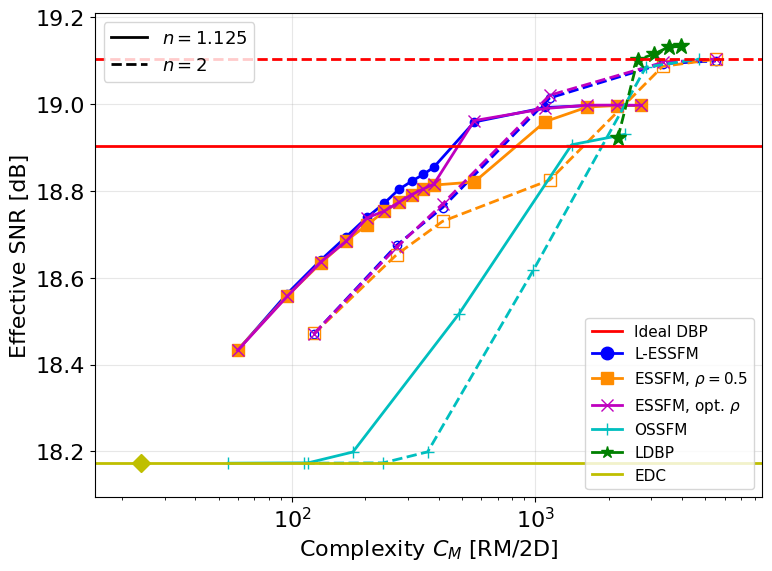

In [7]:
from result_plots import draw
draw(globals(),'complexity')
plt.show()


## 7. Same figure vs number of steps $N_s$

Identical layout, but the x-axis is the number of DBP steps $N_s$ instead of the
complexity. EDC (no DBP steps) and Ideal DBP are horizontal references. LDBP is
shown at its best point (full taps) at $N_s$ = `LDBP_NS`.

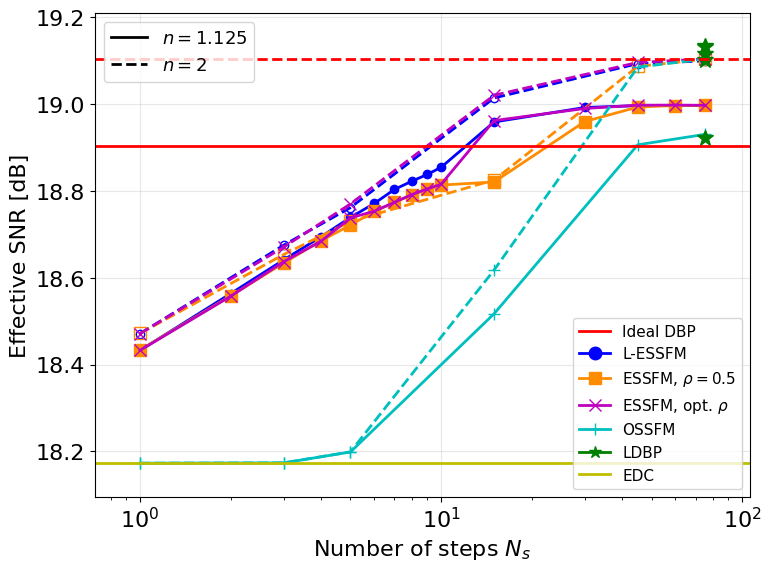

In [8]:
draw(globals(),'steps')
plt.show()
from storage import write_json, digest
summary = {name:globals()[name] for name in ('edc','ideal125','ideal2','lessfm125','lessfm2','essfm125','essfm2','essfmopt125','essfmopt2','ossfm125','ossfm2','ldbp','LDBP_TOTAL_STEPS') if name in globals()}
summary.update(scenario=SCENARIO,powers_dbm=Pgrid.tolist(),forward_manifest_sha256=digest(scenario.forward_dir/'manifest.json'),ase_mode='independent',complete=True)
summary['parameter_hashes'] = {str(p.relative_to(Path(RESDIR))):digest(p) for p in Path(RESDIR).glob('*Ns*/parameters.csv')}
write_json(Path(RESDIR)/'summary.json',summary)
